# Optiver Realized Volatility Prediction —— Kaggle Competition

In [1]:
import polars as pl
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import KFold
import warnings
import os

# ignore unnecessary warnings 
warnings.filterwarnings('ignore')

train_data_dir = r"/Users/dyk/Desktop/desktop/application/Kaggle/optiver-realized-volatility-prediction/book_train.parquet"
train_csv_path = r"/Users/dyk/Desktop/desktop/application/Kaggle/optiver-realized-volatility-prediction/train.csv"

## 1.Feature Engineering
(1) Feature Engineering: Time-Window Aggregation

Simply calculating 10-minute global volatility is not enough. In order to capture recent changes in market sentiment, I slice the timeline and extract statistical features of different time windows. For example, if the volatility in the last 100 seconds is significantly higher than the first 500 seconds, this usually means that the market is accelerating, which is a strong signal. I will build the following window features:

> - volatility_global: the volatility of the whole period (600s)
> - volatility_300_600: the volatility in the last 300 seconds
> - volatility_500_600: the volatility in the last 100 seconds

In [3]:
def get_basic_feature(df_lazy):
    return df_lazy.with_columns([
        # WAP
        ((pl.col("bid_price1") * pl.col("ask_size1") + pl.col("ask_price1") * pl.col("bid_size1")) / (pl.col("bid_size1") + pl.col("ask_size1"))).alias("wap"),
        # Price Spread  
        ((pl.col("ask_price1") / pl.col("bid_price1") - 1).alias("price_spread"))
    ])

# 3. Log return         
def get_log_return(df_lazy):
    return df_lazy.with_columns([
        pl.col("wap").log().diff().over(["time_id"],["stock_id"]).fill_null(0).alias("log_return")
    ])

# Three Volatilities and Mean price spread of the end of the trading session
def get_volatility_aggregation(df_lazy):
    features = [
        # Volatility_global
        (pl.col("log_return") ** 2).sum().sqrt().alias("volatility_global"),
        # volatility_300_600
        (pl.col("log_return").filter(pl.col("seconds_in_bucket") >= 300) ** 2).sum().sqrt().alias("volatility_300_600"),
        # volatility_500_600
        (pl.col("log_return").filter(pl.col("seconds_in_bucket") >= 500) ** 2).sum().sqrt().alias("volatility_500_600"),
        # mean_spread_last
        pl.col("price_spread").filter(pl.col("seconds_in_bucket") >= 500).mean().alias("mean_spread_last")
    ]
    
    return features

q = pl.scan_parquet(train_data_dir, hive_partitioning = True)

df_feature = (q
              .pipe(get_basic_feature)
              .pipe(get_log_return)
              .group_by(["time_id","stock_id"])
              .agg(get_volatility_aggregation(q))
              .collect()
             )

df_feature.head(3)    

time_id,stock_id,volatility_global,volatility_300_600,volatility_500_600,mean_spread_last
i16,i64,f64,f64,f64,f32
14913,62,0.002053,0.00155,0.000685,0.000445
4294,67,0.003807,0.002313,0.001288,0.000588
7632,44,0.017906,0.009341,0.006869,0.000928


(2) Feature Engineering: Market Aggregates

The volatility of an individual stock is rarely insolated, since it is typically influenced by the overall market sentiment. To provide "context" for the model, I calculate market-wide statistical metrics for each specific time slice(time_id).

> - Market Mean Volatility: The average panic level of the market at the current moment.
> - Market Max Volatility: What is the most violent fluctuation in the market at the current moment.
> - Relative Strength: The volatility of an individual stock divided by the average market volatility is used to determine whether the stock is "independent" or "following the crowd".

In [5]:
df_market = (df_feature.group_by("time_id").agg([
    pl.col("volatility_global").mean().alias("market_mean_volatility"),
    pl.col("volatility_global").max().alias("market_max_volatility"),
    pl.col("volatility_global").std().alias("market_std_volatility")
])
            )

df_combined = df_feature.join(df_market, on = "time_id", how = "left")

df_train = pl.read_csv(train_csv_path)
data_full = df_train.join(df_combined, on = ["time_id","stock_id"], how = "inner")

data_full = data_full.with_columns([
    (pl.col("volatility_global") / pl.col("market_mean_volatility")).alias("vol_relative_to_volatility"),
    (pl.col("volatility_500_600") / pl.col("volatility_global")).alias("vol_momentum")                                                                  
])

# convert to Pandas Dateframe to equip LightGBM
df_pandas = data_full.to_pandas()

## 2. Model Training

In here, LightGBM Regressor is used for training. Since the evaluation metric is RMSPE (percentage error), the model is very sensitive to the prediction deviation of small values ​​Target. In order to optimize RMSPE, we need to weight the samples during training, and the weight is inversely proportional to the square of Target:

$$Weight_i = \frac{1}{Target_i^2}$$

This will force the model to pay more attention to those samples with extremely low volatility, thereby reducing the overall percentage error.

In [9]:
#define RMSPE
def rmspe(y_true, y_predict):
    return np.sqrt(np.mean(np.square((y_true - y_predict) / y_true)))

def feval_rmspe(y_pred, lgb_train):
    y_true = lgb_train.get_label()
    return 'RMSPE', rmspe(y_true, y_pred), False

X = df_pandas.drop(columns = ["time_id","target"])
y = df_pandas["target"]
cat_features = ["stock_id"]

# LightGBM parameters
params = {
    'learning_rate': 0.05,
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'num_leaves': 128,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'n_jobs': -1,
    'seed': 42,
    'verbosity': -1
}

kf = KFold(n_splits = 5, shuffle = True, random_state = 0)
scores = []

for fold, (train_idx,val_idx) in enumerate(kf.split(X,y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    w_train = 1.0 / np.square(y_train)
    w_val = 1.0 / np.square(y_val)

    train_set = lgb.Dataset(X_train, y_train, weight = w_train, categorical_feature = cat_features)
    val_set = lgb.Dataset(X_val, y_val, weight = w_val, categorical_feature = cat_features)

    model = lgb.train(
        params,
        train_set,
        num_boost_round = 1000,
        valid_sets = [train_set, val_set],
        callbacks = [lgb.early_stopping(50), lgb.log_evaluation(0)],
        feval=feval_rmspe
    )

    preds = model.predict(X_val)
    score = rmspe(y_val, preds)
    scores.append(score)
    print(f"Fold {fold+1} RMSPE: {score:.5f}")

print(f"\n>>> Average RMSPE: {np.mean(scores):.5f}")

    

Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[999]	training's rmse: 0.000374803	training's RMSPE: 0.173791	valid_1's rmse: 0.000472055	valid_1's RMSPE: 0.216818
Fold 1 RMSPE: 0.21682
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	training's rmse: 0.000374974	training's RMSPE: 0.173609	valid_1's rmse: 0.000460466	valid_1's RMSPE: 0.212783
Fold 2 RMSPE: 0.21278
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[999]	training's rmse: 0.000377135	training's RMSPE: 0.174302	valid_1's rmse: 0.000493115	valid_1's RMSPE: 0.229476
Fold 3 RMSPE: 0.22948
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[623]	training's rmse: 0.000401489	training's RMSPE: 0.185444	valid_1's rmse: 0.000476398	valid_1's RMSPE: 0.222231
Fold 4 RMSPE: 0.22223
Training until validatio

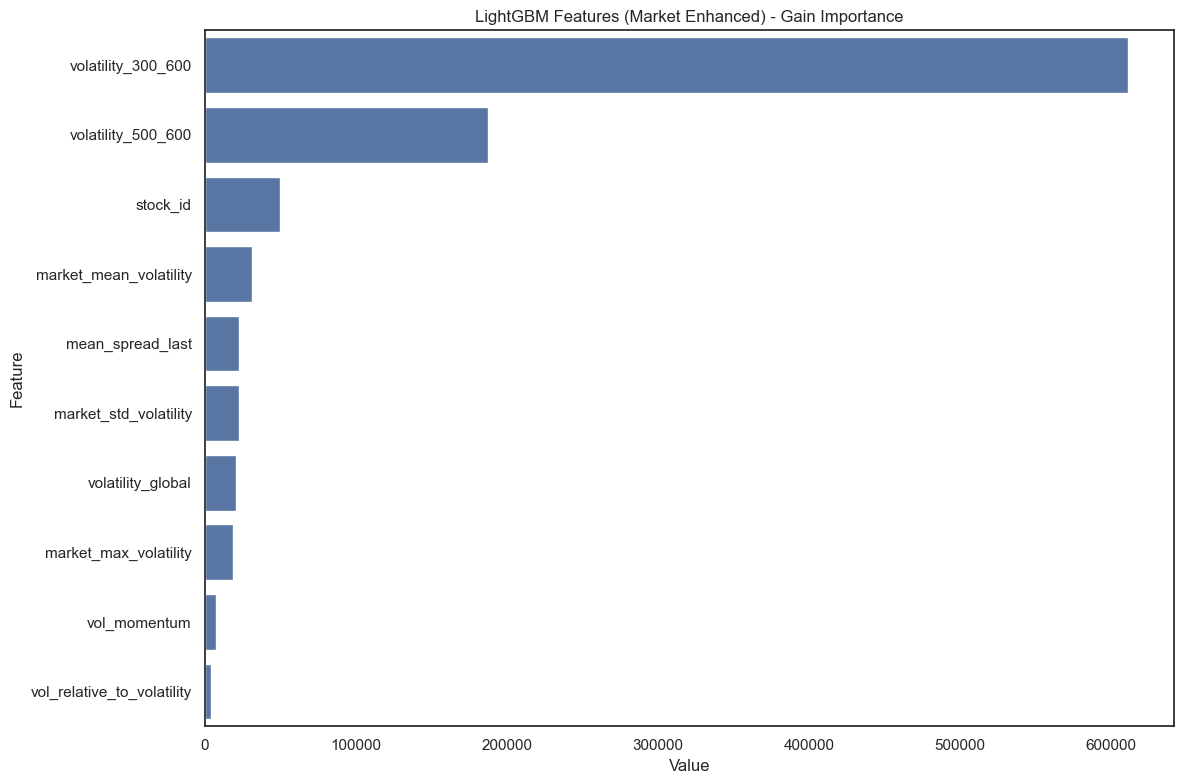

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="white") 
plt.rcParams["axes.unicode_minus"] = False
feature_imp = pd.DataFrame(
    sorted(zip(model.feature_importance(importance_type="gain"), X.columns)),
    columns=["Value", "Feature"],
)

plt.figure(figsize=(12, 8))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
plt.title('LightGBM Features (Market Enhanced) - Gain Importance')
plt.tight_layout()
plt.show()

In [17]:
feature_imp 

,Value,Feature
0,3941.472525,vol_relative_to_volatility
1,7048.275127,vol_momentum
2,18835.158431,market_max_volatility
3,20690.639906,volatility_global
4,22201.844287,market_std_volatility
5,22496.597945,mean_spread_last
6,31100.401531,market_mean_volatility
7,49751.167519,stock_id
8,187621.849639,volatility_500_600
9,610992.936951,volatility_300_600


## 3. Inference & Submission
In this pharse, the following principles need to strictly adhere:
> 1. Feature Consistency: The features generated by the test set must be completely consistent with the training set, including the name of the feature, calculation logic and order of columns.\n",
> 2. Dynamic Market Features: Since the test set arrives in batches, we need to calculate market volatility (Market Aggregates) in real time based on the data of the current test batch to capture the current market sentiment.\n",
> 3. Safety Lock: Forces alignment of feature column order to prevent prediction errors caused by column name misalignment."

In [19]:
if 'X' in locals():
    train_cols = X.columns.tolist()
else:
    train_cols = ['volatility_global', 'volatility_300_600', 'volatility_500_600', 
                  'mean_spread_last', 'market_mean_volatility', 'market_max_volatility', 
                  'market_std_volatility', 'vol_relative_to_volatility', 'vol_momentum', ]

test_data_dir = r"/Users/dyk/Desktop/desktop/application/Kaggle/optiver-realized-volatility-prediction/book_test.parquet"
test_csv_path = r"/Users/dyk/Desktop/desktop/application/Kaggle/optiver-realized-volatility-prediction/test.csv"

def get_test_features(test_dir, test_csv_path):
    
    df_test_base = pl.read_csv(test_csv_path)
    q_test = pl.scan_parquet(test_dir, hive_partitioning=True)

    df_feats = (
        q_test
        .pipe(get_basic_feature)
        .pipe(get_log_return)
        .group_by(["stock_id", "time_id"])
        .agg(get_volatility_aggregation(q_test))
        .collect()
    )

    df_market = (df_feats.group_by("time_id").agg([
    pl.col("volatility_global").mean().alias("market_mean_volatility"),
    pl.col("volatility_global").max().alias("market_max_volatility"),
    pl.col("volatility_global").std().alias("market_std_volatility")
    ])
            )

    df_enhanced = df_feats.join(df_market, on="time_id", how="left")
    data_test = df_test_base.join(df_enhanced, on=["stock_id", "time_id"], how="left")

    data_test =  data_test.with_columns([
        (pl.col("volatility_global") / pl.col("market_mean_volatility")).alias("vol_relative_to_volatility"),
        (pl.col("volatility_500_600") / pl.col("volatility_global")).alias("vol_momentum")                                                                  
    ])

    data_test = data_test.fill_nan(0).fill_null(0)

    return data_test

df_test_final = get_test_features(test_data_dir, test_csv_path)
X_test = df_test_final.to_pandas()
X_test_input = X_test[train_cols]
pred_values = model.predict(X_test_input)

submission = pd.DataFrame({
    "row_id": df_test_final["row_id"].to_list(),
    "target": pred_values
})

submission.to_csv('submission.csv', index=False)
print(submission)
    

  row_id    target
0    0-4  0.001054
1   0-32  0.000988
2   0-34  0.000988
